#  <span style="color:#C133FF"> Loading final optimized results for all participants and loading together! </span> 


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import nibabel as nib
from pathlib import Path

In [2]:
import os, sys, importlib
parent_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(parent_dir)
print(parent_dir)

c:\Users\Admin\Documents\msc_project\Image-processing-strategies


In [3]:
import monkey_tools.extract_metric
importlib.reload(monkey_tools.extract_metric)

from monkey_tools.extract_metric import cnr_wm_gm # re-import updated function

In [4]:
# Loading the simulated related data

sub_db035_fitted_dmod_field_Hz_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\db0_035\mb_r1_solver_n_pad_constant_cropped\fitted_field_demod_Hz.nii.gz").get_fdata()
sub_db035_vert_levels_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\sim\for_rosenberg\cord_levels_crop.nii.gz").get_fdata()

sub_db033_fitted_dmod_field_Hz_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\db0_033\mb_r1_solver_n_pad_constants_cropped\fitted_field_demod_Hz.nii.gz").get_fdata()
sub_db033_vert_levels_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\sim\for_rosenberg\cord_levels_crop.nii.gz").get_fdata()

sub_chi027_fitted_dmod_field_Hz_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\rosenberg_results\chi_027\mb_r1_solver_n_pad_constant_cropped\fitted_field_demod_Hz.nii.gz").get_fdata()
sub_chi027_vert_levels_data = nib.load(r"R:\soothsayer\msc_data\chi_fitting\chi_027\niftis\t1w\for_rosenberg\cord_levels_crop.nii.gz").get_fdata()

In [5]:
# Loading the in-vivo related measured data - this should be already from 2 to 14
sub_db035_in_vivo_dmod_exp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\chi_035_for_rosenberg\sub-2_OLD_Aspire_DEMOD_EXP_mean_per_level_1_15.csv")
sub_db035_in_vivo_dmod_inspp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_035\chi_035_for_rosenberg\sub-2_OLD_Aspire_DEMOD_INSP_mean_per_level_1_15.csv")

sub_db033_in_vivo_dmod_exp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\exp\sub-1_OLD_Aspire_DEMOD_EXP_mean_per_level_1_15.csv")
sub_db033_in_vivo_dmod_inspp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\reprocessing_old_ASPIRE\db0_033\insp\sub-1_OLD_Aspire_DEMOD_INSP_mean_per_level_1_15.csv")

sub_chi027_in_vivo_dmod_exp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\for_rosenberg_transfer\chi_027\measured\sub-16_clearswi_DEMOD_EXP_mean_per_level_1_15.csv")
sub_chi027_in_vivo_dmod_inspp_field_Hz_df = pd.read_csv(r"R:\soothsayer\msc_data\chi_fitting\for_rosenberg_transfer\chi_027\measured\sub-16_clearswi_DEMOD_INSP_mean_per_level_1_15.csv")

In [6]:
sub_db035_demod_avg_respiration = (sub_db035_in_vivo_dmod_exp_field_Hz_df+ sub_db035_in_vivo_dmod_inspp_field_Hz_df )/2
sub_db033_demod_avg_respiration = (sub_db033_in_vivo_dmod_exp_field_Hz_df+ sub_db033_in_vivo_dmod_inspp_field_Hz_df )/2
sub_chi027_demod_avg_respiration = (sub_chi027_in_vivo_dmod_exp_field_Hz_df+ sub_chi027_in_vivo_dmod_inspp_field_Hz_df )/2

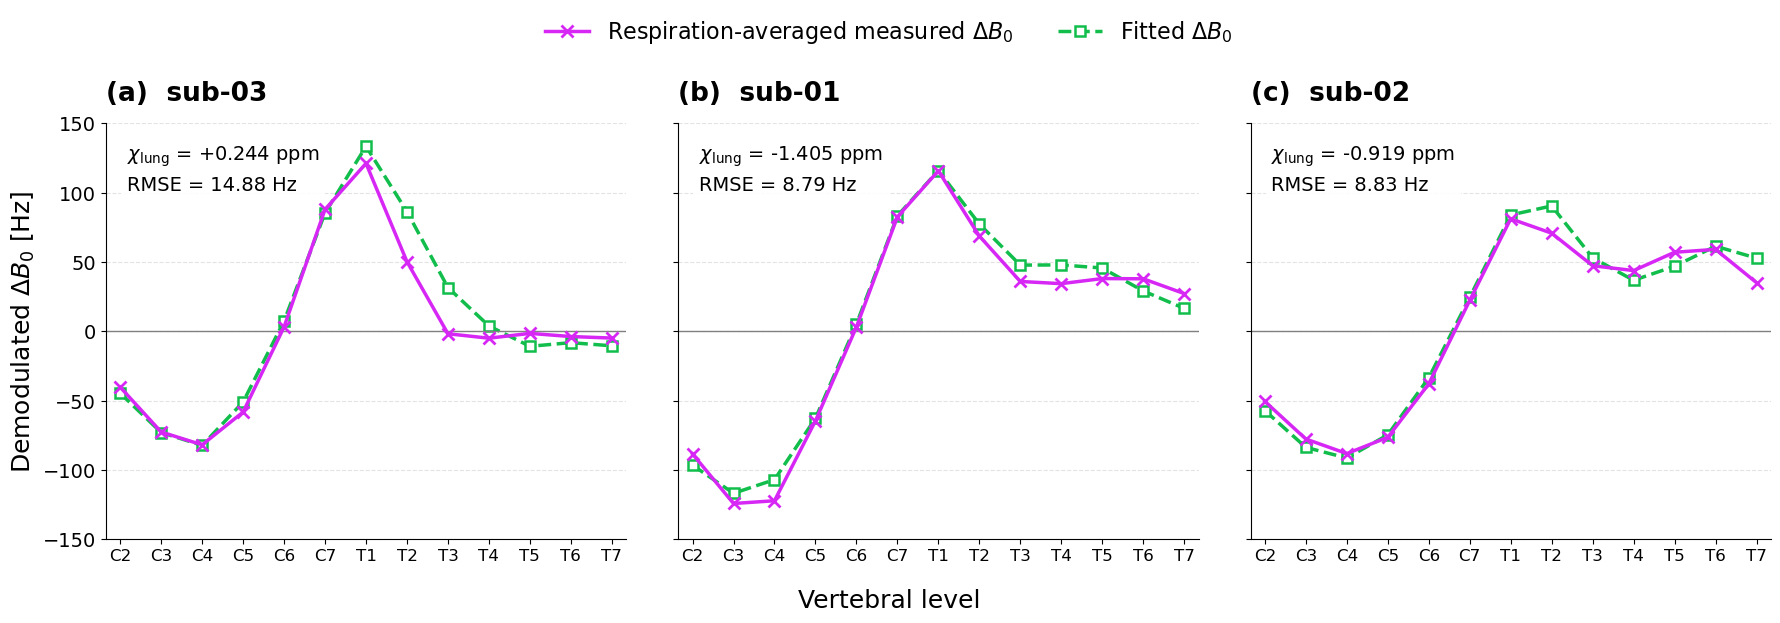

In [11]:
levels = [f"C{i}" for i in range(2, 8)] + [f"T{i}" for i in range(1, 8)]
level_ids = np.arange(2, 15)
x = np.arange(len(levels))

display_names = {
    "chi_027": "sub-03",
    "db0_033": "sub-01",
    "db0_035": "sub-02",
}


# Fitted χ values from the cropped runs shown above.
participants = {
    "chi_027": {
        "field": sub_chi027_fitted_dmod_field_Hz_data,
        "labels": sub_chi027_vert_levels_data,
        "exp": sub_chi027_in_vivo_dmod_exp_field_Hz_df,
        "insp": sub_chi027_in_vivo_dmod_inspp_field_Hz_df,
        "chi": 0.2438,
    },
    "db0_033": {
        "field": sub_db033_fitted_dmod_field_Hz_data,
        "labels": sub_db033_vert_levels_data,
        "exp": sub_db033_in_vivo_dmod_exp_field_Hz_df,
        "insp": sub_db033_in_vivo_dmod_inspp_field_Hz_df,
        "chi": -1.4054,
    },
    "db0_035": {
        "field": sub_db035_fitted_dmod_field_Hz_data,
        "labels": sub_db035_vert_levels_data,
        "exp": sub_db035_in_vivo_dmod_exp_field_Hz_df,
        "insp": sub_db035_in_vivo_dmod_inspp_field_Hz_df,
        "chi": -0.9194,
    },
}

# Measured CSV rows are already ordered C2–T7.
# Average only the field values, not entire DataFrames.
profiles = {}

for participant, data in participants.items():
    measured = (
        data["exp"]["dmod_B0_Hz"].to_numpy(dtype=float)
        + data["insp"]["dmod_B0_Hz"].to_numpy(dtype=float)
    ) / 2

    field = data["field"]
    labels = data["labels"]

    if field.shape != labels.shape:
        raise ValueError(f"{participant}: field and cord mask shapes differ")
    if measured.shape != (13,):
        raise ValueError(f"{participant}: expected 13 measured values, C2–T7")

    # Calculate voxel means for all cord levels in one pass.
    selected = (labels >= 2) & (labels <= 14)
    cord_labels = labels[selected].astype(np.int64)
    counts = np.bincount(cord_labels, minlength=15)
    sums = np.bincount(
        cord_labels, weights=field[selected], minlength=15
    )

    if np.any(counts[level_ids] == 0):
        raise ValueError(f"{participant}: one or more cord levels are missing")

    fitted = sums[level_ids] / counts[level_ids]

    profiles[participant] = {
        "measured": measured,
        "fitted": fitted,
        "chi": data["chi"],
        "rmse": np.sqrt(np.mean((fitted - measured) ** 2)),
    }

# Both profiles are already demodulated: do not demodulate again.
style = {
    "font.size": 15,
    "axes.titlesize": 19,
    "axes.labelsize": 18,
    "xtick.labelsize": 12,
    "ytick.labelsize": 14,
    "legend.fontsize": 16,
    "lines.linewidth": 2.5,
    "lines.markersize": 8,
}

all_values = np.concatenate([
    p[key] for p in profiles.values() for key in ("measured", "fitted")
])
ylim = (
    25 * np.floor((all_values.min() - 12) / 25),
    25 * np.ceil((all_values.max() + 12) / 25),
)

with plt.rc_context(style):
    fig, axes = plt.subplots(
        1, 3, figsize=(18, 6.4), sharex=True, sharey=True
    )

    for index, (ax, (participant, p)) in enumerate(
        zip(axes, profiles.items())
    ):
        ax.plot(
            x, p["measured"], "x-", color="#D627F5",
            markeredgewidth=2,
            label=r"Respiration-averaged measured $\Delta B_0$",
            zorder=3,
        )
        ax.plot(
            x, p["fitted"], "s--", color="#11BD4B",
            markerfacecolor="white", markeredgewidth=1.8,
            markersize=6.5, label=r"Fitted $\Delta B_0$",
            zorder=2,
        )

        ax.set_title(
            f"({chr(97 + index)})  {display_names[participant]}",
            loc="left", pad=16, fontweight="semibold",
        )
        ax.text(
            0.04, 0.95,
            rf'$\chi_{{\mathrm{{lung}}}}$ = {p["chi"]:+.3f} ppm'
            + "\n" + f'RMSE = {p["rmse"]:.2f} Hz',
            transform=ax.transAxes, va="top", fontsize=14,
            linespacing=1.5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.9),
        )

        ax.set_xticks(x, levels)
        ax.set(xlim=(-0.35, 12.35), ylim=ylim)
        ax.axhline(0, color="gray", linewidth=1)
        ax.grid(axis="y", linestyle="--", alpha=0.35)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel(r"Demodulated $\Delta B_0$ [Hz]")
    fig.supxlabel("Vertebral level", y=0.035)

    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, legend_labels,
        loc="upper center", bbox_to_anchor=(0.5, 0.995),
        ncol=2, frameon=False,
    )
    fig.subplots_adjust(
        left=0.065, right=0.99, bottom=0.15, top=0.80, wspace=0.10
    )

    # Optional:
    # fig.savefig("measured_fitted_panels.png", dpi=300, bbox_inches="tight")

    plt.show()

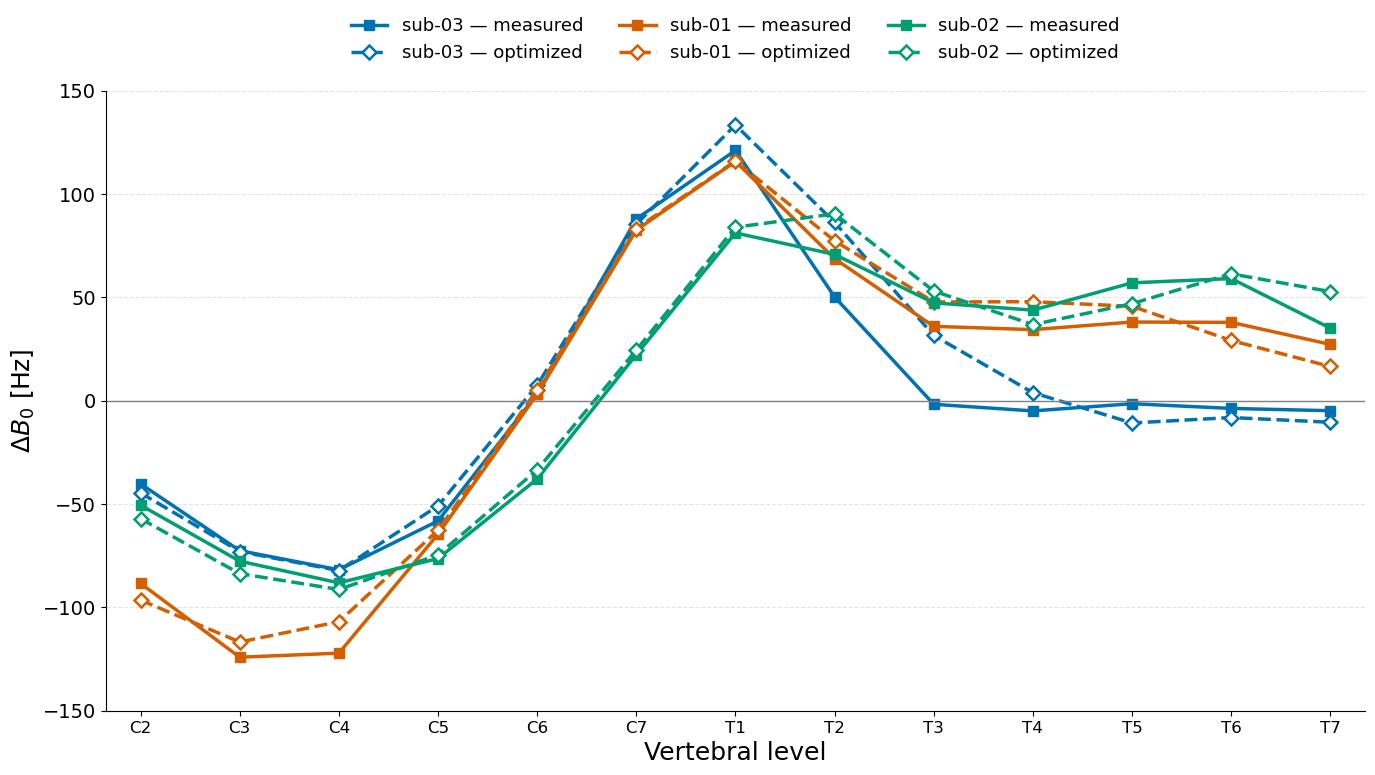

In [13]:
participant_colours = {
    "chi_027": "#0072B2",
    "db0_033": "#D55E00",
    "db0_035": "#009E73",
}

with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=(14, 8))

    for participant, p in profiles.items():
        colour = participant_colours[participant]

        ax.plot(
            x, p["measured"],
            color=colour, linestyle="-", marker="s",
            markersize=7,
            label=f"{display_names[participant]} — measured",
        )
        ax.plot(
            x, p["fitted"],
            color=colour, linestyle="--", marker="D",
            markersize=7, markerfacecolor="white",
            markeredgewidth=1.8,
            label=f"{display_names[participant]} — optimized",
        )

    ax.set_xticks(x, levels)
    ax.set(
        xlabel="Vertebral level",
        ylabel=r"$\Delta B_0$ [Hz]",
        xlim=(-0.35, 12.35),
        ylim=ylim,
    )

    ax.axhline(0, color="gray", linewidth=1)
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.spines[["top", "right"]].set_visible(False)

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=3, frameon=False, fontsize=13,
    )

    fig.tight_layout()

    # Optional:
    # fig.savefig("measured_fitted_combined.png", dpi=300, bbox_inches="tight")

    plt.show()